# 🔓 Solutions: Capstone Project

> **Try first, peek second.** You learn far more by struggling with a problem for ten minutes than by reading its answer for ten seconds. Use these solutions to *compare* your approach, not to replace it. There is often more than one correct way.


In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

### 🧩 Milestone 10.1: Understand the data &nbsp; ⭐⭐

Before modelling, **explore**. The data is loaded for you in `cars`.

1. `missing_counts`: a pandas Series with the **number of missing values for each column that has any** (skip columns with none).
2. `priciest_brand`: the brand with the highest **median** `price_usd`.
3. `corr_with_price`: a Series of the correlation of `year`, `mileage_km`, `engine_cc`, `owners` with `price_usd`.
4. **Make two plots** (not auto-checked, but your report will need them): (a) price vs. year, (b) median price by brand (bar chart). What patterns do you see? Is the price distribution symmetric or skewed?

missing values:
 mileage_km    41
engine_cc     30
owners        21

median price by brand:
 brand
Kia       4871.0
Ford      5015.0
Honda     5766.0
Toyota    6591.5
BMW       8859.0

correlation with price:
 year          0.83
mileage_km   -0.77
engine_cc     0.03
owners       -0.03


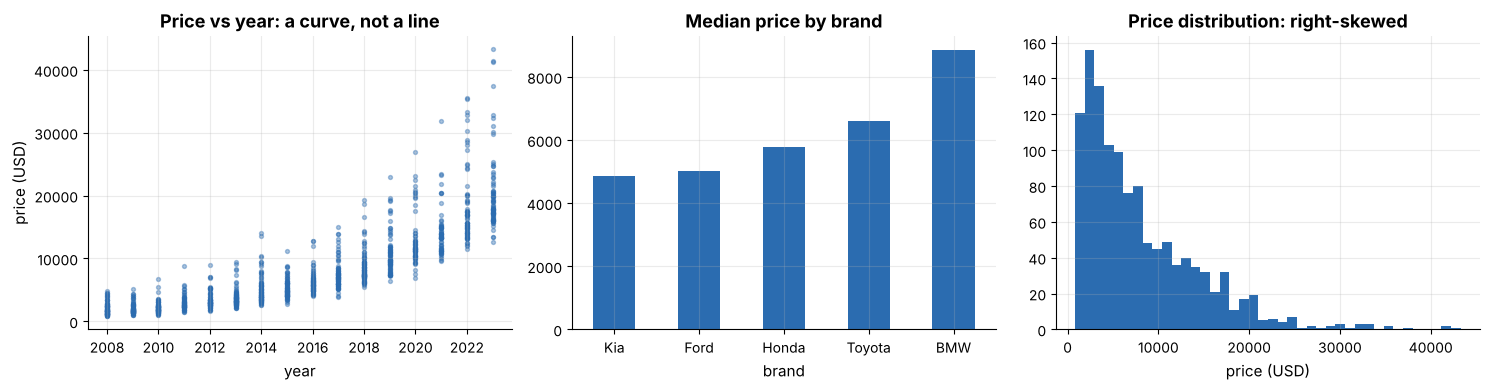

In [2]:
cars = load("used_cars.csv")

nulls = cars.isna().sum()
missing_counts = nulls[nulls > 0]
priciest_brand = cars.groupby("brand")["price_usd"].median().idxmax()
corr_with_price = cars[["year", "mileage_km", "engine_cc", "owners", "price_usd"]].corr()["price_usd"].drop("price_usd")

print("missing values:\n", missing_counts.to_string())
print("\nmedian price by brand:\n", cars.groupby("brand")["price_usd"].median().sort_values().to_string())
print("\ncorrelation with price:\n", corr_with_price.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(cars["year"], cars["price_usd"], s=8, alpha=0.4); axes[0].set_xlabel("year"); axes[0].set_ylabel("price (USD)"); axes[0].set_title("Price vs year: a curve, not a line")
cars.groupby("brand")["price_usd"].median().sort_values().plot.bar(ax=axes[1], color=BLUE); axes[1].set_title("Median price by brand"); axes[1].tick_params(axis="x", rotation=0)
axes[2].hist(cars["price_usd"], bins=40, color=BLUE); axes[2].set_title("Price distribution: right-skewed"); axes[2].set_xlabel("price (USD)")
plt.tight_layout(); plt.show()

In [3]:
# ✔ Self-check
check("three columns have missing values", lambda: set(missing_counts.index) == {"mileage_km", "engine_cc", "owners"})
check("missing counts are 41 / 30 / 21", lambda: missing_counts["mileage_km"] == 41 and missing_counts["engine_cc"] == 30 and missing_counts["owners"] == 21)
check("BMW is the priciest brand", lambda: priciest_brand == "BMW")
check("newer cars cost more (corr(year) > 0.5)", lambda: corr_with_price["year"] > 0.5)
check("higher mileage means lower price (corr < 0)", lambda: corr_with_price["mileage_km"] < 0)

✅ PASSED   three columns have missing values
✅ PASSED   missing counts are 41 / 30 / 21
✅ PASSED   BMW is the priciest brand
✅ PASSED   newer cars cost more (corr(year) > 0.5)
✅ PASSED   higher mileage means lower price (corr < 0)


True

**🧑‍🏫 Walkthrough.** Key discoveries: (1) three columns have a few percent missing (we need imputation; (2) BMWs are the most expensive by a margin; (3) price falls with age and mileage, but the price-vs-year plot is **curved** (depreciation is proportional) each year the car loses a *percentage* of its value, so the scatter bends and fans out), and (4) the price distribution is **right-skewed**. Remember these last two observations: they are the clue to Milestone 5.

### 🧩 Milestone 10.2: Split the data and set a baseline &nbsp; ⭐⭐

1. Separate `X` (all columns except `price_usd`) and `y` (`price_usd`), and split **80/20** with `random_state=0` → `X_train, X_test, y_train, y_test`.
2. Fit a `DummyRegressor(strategy="mean")` on the **training** data and compute its **test** RMSE (`baseline_rmse`) and MAE (`baseline_mae`).

*This baseline is the number every model must beat. Write it down: you will quote it in your report.*

In [4]:
X = cars.drop(columns="price_usd")
y = cars["price_usd"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_rmse = rmse(y_test, dummy.predict(X_test))
baseline_mae = mean_absolute_error(y_test, dummy.predict(X_test))
print(f"BASELINE (always guess ${y_train.mean():,.0f}):  RMSE = ${baseline_rmse:,.0f},  MAE = ${baseline_mae:,.0f}")

BASELINE (always guess $7,828):  RMSE = $6,687,  MAE = $4,862


In [5]:
# ✔ Self-check
check("960 train / 240 test rows", lambda: len(X_train) == 960 and len(X_test) == 240)
check("split is reproducible (same as random_state=0)", lambda: list(X_test.index) == list(train_test_split(X, y, test_size=0.2, random_state=0)[1].index))
check("baseline RMSE ≈ 6,687", lambda: abs(baseline_rmse - 6686.6) < 1)
check("baseline MAE ≈ 4,862", lambda: abs(baseline_mae - 4861.9) < 1)

✅ PASSED   960 train / 240 test rows
✅ PASSED   split is reproducible (same as random_state=0)
✅ PASSED   baseline RMSE ≈ 6,687
✅ PASSED   baseline MAE ≈ 4,862


True

**🧑‍🏫 Walkthrough.** Guessing the average price (~$7,800) misses by about **$4.9k on average**: a huge error for cars that sell for $3–15k. That's the bar to clear. (Notice we computed it on the *test* set but fitted on *train*; the baseline is a model like any other.)

### 🧩 Milestone 10.3: Build a leakage-proof preprocessing pipeline &nbsp; ⭐⭐⭐

Using the toolkit from the primer:

1. Define `num_cols = ["year", "mileage_km", "engine_cc", "owners"]` and `cat_cols = ["brand", "fuel_type", "transmission"]`.
2. Build `preprocess`, a `ColumnTransformer` that
   * sends numeric columns through `SimpleImputer(strategy="median")` then `StandardScaler()`,
   * sends categorical columns through `SimpleImputer(strategy="most_frequent")` then `OneHotEncoder(handle_unknown="ignore")`.
3. Build `lin_pipe = make_pipeline(preprocess, LinearRegression())`, **fit it on the training data**, and store its **test RMSE** in `lin_test_rmse`.

In [6]:
num_cols = ["year", "mileage_km", "engine_cc", "owners"]
cat_cols = ["brand", "fuel_type", "transmission"]

preprocess = ColumnTransformer([
    ("numbers", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("text", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat_cols),
])
lin_pipe = make_pipeline(preprocess, LinearRegression()).fit(X_train, y_train)
lin_test_rmse = rmse(y_test, lin_pipe.predict(X_test))
print(f"linear regression, test RMSE = ${lin_test_rmse:,.0f}   (baseline ${baseline_rmse:,.0f})")
print("number of columns after preprocessing:", lin_pipe[0].transform(X_test).shape[1])

linear regression, test RMSE = $2,944   (baseline $6,687)
number of columns after preprocessing: 14


In [7]:
# ✔ Self-check
check("preprocess is a ColumnTransformer", lambda: isinstance(preprocess, ColumnTransformer))
check("the pipeline is fitted and predicts without errors on data with NaNs", lambda: len(lin_pipe.predict(X_test)) == 240)
check("one-hot columns appear: 4 numeric + 5 brands + 3 fuels + 2 transmissions = 14", lambda: lin_pipe[0].transform(X_test).shape[1] == 14)
check("beats the baseline by a wide margin (RMSE < 50% of baseline)", lambda: lin_test_rmse < 0.5 * baseline_rmse)

✅ PASSED   preprocess is a ColumnTransformer
✅ PASSED   the pipeline is fitted and predicts without errors on data with NaNs
✅ PASSED   one-hot columns appear: 4 numeric + 5 brands + 3 fuels + 2 transmissions = 14
✅ PASSED   beats the baseline by a wide margin (RMSE < 50% of baseline)


True

**🧑‍🏫 Walkthrough.** Every learned quantity (medians, most-frequent categories, scaling statistics, and the regression weights) comes from **training rows only**, because it all lives inside one pipeline fitted on `X_train`. The very first model already cuts the baseline error by more than half. The 14 columns are 4 numeric + 5 brands + 3 fuel types + 2 transmissions.

### 🧩 Milestone 10.4: Compare models with cross-validation &nbsp; ⭐⭐⭐

Compare four model families using **5-fold cross-validation on the training set only**, with `KFold(n_splits=5, shuffle=True, random_state=0)` and `scoring="neg_root_mean_squared_error"`.

Each model must be wrapped in its own pipeline with a **clone of `preprocess`**:

| Name | Model |
|---|---|
| `"Linear"` | `LinearRegression()` |
| `"Ridge"` | `Ridge(alpha=1)` |
| `"KNN"` | `KNeighborsRegressor(n_neighbors=10)` |
| `"Tree"` | `DecisionTreeRegressor(max_depth=6, random_state=0)` |

Store the **mean CV RMSE** (positive numbers!) in `cv_rmse` (`{name: rmse}`) and the best model's name in `best_name`.

In [8]:
kf = KFold(n_splits=5, shuffle=True, random_state=0)
candidates = {"Linear": LinearRegression(), "Ridge": Ridge(alpha=1),
              "KNN": KNeighborsRegressor(n_neighbors=10),
              "Tree": DecisionTreeRegressor(max_depth=6, random_state=0)}

cv_rmse = {}
for name, reg in candidates.items():
    pipe = make_pipeline(clone(preprocess), reg)
    cv_rmse[name] = -cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error").mean()

best_name = min(cv_rmse, key=cv_rmse.get)
print({k: round(v) for k, v in cv_rmse.items()}, "→ best:", best_name)

{'Linear': 2628, 'Ridge': 2628, 'KNN': 2284, 'Tree': 1697} → best: Tree


In [9]:
# ✔ Self-check
check("four models evaluated", lambda: sorted(cv_rmse) == ["KNN", "Linear", "Ridge", "Tree"])
check("best_name is the model with the lowest CV RMSE", lambda: best_name == min(cv_rmse, key=cv_rmse.get))
check("the non-linear Tree beats Linear (the data is not linear in price)", lambda: cv_rmse["Tree"] < cv_rmse["Linear"])
check("Linear and Ridge are practically identical (within 2%)", lambda: abs(cv_rmse["Linear"] - cv_rmse["Ridge"]) / cv_rmse["Linear"] < 0.02)

✅ PASSED   four models evaluated
✅ PASSED   best_name is the model with the lowest CV RMSE
✅ PASSED   the non-linear Tree beats Linear (the data is not linear in price)
✅ PASSED   Linear and Ridge are practically identical (within 2%)


True

**🧑‍🏫 Walkthrough.** The Tree wins (~$1.7k) (far ahead of Linear/Ridge (~$2.6k)) **but something should bother you**: a linear model is usually hard to beat when relationships are simple, so the fact that a *tree* wins suggests the linear model is missing a **non-linear structure** in the data. That's a diagnostic clue, not just a leaderboard. Ridge ≈ Linear because with 960 rows and 14 features there is little overfitting for regularisation to fix.

### 🧩 Milestone 10.5: Improve the model by thinking: transform the target &nbsp; ⭐⭐⭐

*Clue from Milestone 1:* depreciation is **proportional**: a car loses a *percentage* of its value each year, and prices are right-skewed. When effects **multiply**, taking **logarithms** turns them into effects that **add**: which is exactly what a linear model handles.

Wrap the linear pipeline so that the model learns **log(price)** but predicts in **dollars**:

```python
TransformedTargetRegressor(regressor=<your linear pipeline>, func=np.log, inverse_func=np.exp)
```

Compute its 5-fold CV RMSE (same `kf`, **in dollars**, positive) → `cv_rmse_log`. Store the relative improvement over the plain linear model in `gain_pct = 100 * (cv_rmse["Linear"] − cv_rmse_log) / cv_rmse["Linear"]`.

In [10]:
log_linear = TransformedTargetRegressor(
    regressor=make_pipeline(clone(preprocess), LinearRegression()),
    func=np.log, inverse_func=np.exp)

cv_rmse_log = -cross_val_score(log_linear, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error").mean()
gain_pct = 100 * (cv_rmse["Linear"] - cv_rmse_log) / cv_rmse["Linear"]
print(f"plain linear: ${cv_rmse['Linear']:,.0f}   →   log-target linear: ${cv_rmse_log:,.0f}   ({gain_pct:.0f}% better)")
print(f"for reference, the best tree: ${cv_rmse['Tree']:,.0f}")

plain linear: $2,628   →   log-target linear: $1,080   (59% better)
for reference, the best tree: $1,697


In [11]:
# ✔ Self-check
check("a TransformedTargetRegressor was built", lambda: isinstance(log_linear, TransformedTargetRegressor))
check("log-target linear model has CV RMSE < 1,300", lambda: cv_rmse_log < 1300)
check("it beats the non-linear Tree too", lambda: cv_rmse_log < cv_rmse["Tree"])
check("improvement over plain linear is > 50%", lambda: gain_pct > 50)

✅ PASSED   a TransformedTargetRegressor was built
✅ PASSED   log-target linear model has CV RMSE < 1,300
✅ PASSED   it beats the non-linear Tree too
✅ PASSED   improvement over plain linear is > 50%


True

**🧑‍🏫 Walkthrough.** **A one-line idea beat a more "powerful" model.** On a log scale, "loses ~10% of its value per year" becomes "loses a constant amount of log-price per year", a straight line. The same linear model, fed the right target, drops from ~$2.6k to ~$1.1k: better than the tree. *Lesson: understanding the data-generating process often beats trying fancier algorithms.* (Also note: errors on the log scale are *relative* errors, which is exactly how car buyers think about price.)

### 🧩 Milestone 10.6: Tune hyperparameters (on training data only!) &nbsp; ⭐⭐⭐

Tune the **Ridge** strength for the log-target model with `GridSearchCV`:

* estimator: a `TransformedTargetRegressor` wrapping `make_pipeline(clone(preprocess), Ridge())`, `func=np.log`, `inverse_func=np.exp`;
* parameter grid: the Ridge `alpha` in `[0.01, 0.1, 1, 10, 100]`: the parameter name is **`"regressor__ridge__alpha"`** (outer step `regressor`, then the pipeline's step `ridge`);
* `cv=kf`, `scoring="neg_root_mean_squared_error"`, fitted on the **training set**.

Store the fitted search in `grid`, the winning alpha in `best_alpha`, and the winning CV RMSE (positive) in `best_cv_rmse`.

In [12]:
est = TransformedTargetRegressor(regressor=make_pipeline(clone(preprocess), Ridge()), func=np.log, inverse_func=np.exp)
grid = GridSearchCV(est, {"regressor__ridge__alpha": [0.01, 0.1, 1, 10, 100]}, cv=kf,
                    scoring="neg_root_mean_squared_error").fit(X_train, y_train)

best_alpha = grid.best_params_["regressor__ridge__alpha"]
best_cv_rmse = -grid.best_score_
for p, s in zip(grid.cv_results_["params"], -grid.cv_results_["mean_test_score"]):
    print(f"alpha = {p['regressor__ridge__alpha']:<6}  CV RMSE = ${s:,.0f}")
print(f"\nbest alpha = {best_alpha};  CV RMSE = ${best_cv_rmse:,.0f}")

alpha = 0.01    CV RMSE = $1,080
alpha = 0.1     CV RMSE = $1,080
alpha = 1       CV RMSE = $1,079
alpha = 10      CV RMSE = $1,110
alpha = 100     CV RMSE = $1,968

best alpha = 1;  CV RMSE = $1,079


In [13]:
# ✔ Self-check
check("grid search was run on 5 alphas", lambda: len(grid.cv_results_["params"]) == 5)
check("best_alpha is one of the candidates", lambda: best_alpha in [0.01, 0.1, 1, 10, 100])
check("tuned CV RMSE < 1,150", lambda: best_cv_rmse < 1150)
check("very strong regularisation (α = 100) was NOT best", lambda: best_alpha != 100)

✅ PASSED   grid search was run on 5 alphas
✅ PASSED   best_alpha is one of the candidates
✅ PASSED   tuned CV RMSE < 1,150
✅ PASSED   very strong regularisation (α = 100) was NOT best


True

**🧑‍🏫 Walkthrough.** `GridSearchCV` cross-validates every candidate on the training set and refits the winner on all of the training data (available as `grid.best_estimator_`). The gains from tuning are negligible here: any α up to 1 gives essentially the same error (differences of a dollar or two), α = 10 is slightly worse, and α = 100 is clearly too strong (underfitting, ≈ $900 worse). The model is simple and the data plentiful: an honest finding: **not every tuning step pays off**, and reporting that is part of good practice. The test set is still sealed.

### 🧩 Milestone 10.7: The moment of truth: final test evaluation &nbsp; ⭐⭐⭐

**Open the sealed envelope: once.** Take the tuned model `grid.best_estimator_` and evaluate it on the **test set**:

* `final_metrics`: a dictionary with keys `"MAE"`, `"RMSE"`, `"R2"`, `"MAPE"` (as a fraction, e.g. 0.07 = 7%);
* `improvement_pct`: % reduction of the test RMSE relative to `baseline_rmse`.

Also draw a **predicted-vs-actual** plot and a **residual plot** for the test set.

TEST:  MAE $634   RMSE $1,441   R² 0.953   MAPE 6.9%
Baseline RMSE $6,687  →  model RMSE $1,441  (78% better)


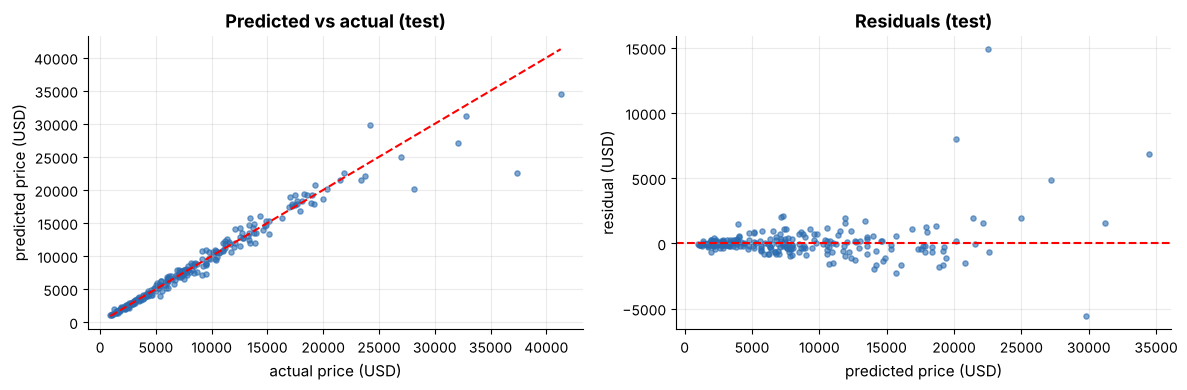

In [14]:
final_model = grid.best_estimator_
final_pred = final_model.predict(X_test)
final_metrics = {"MAE": mean_absolute_error(y_test, final_pred), "RMSE": rmse(y_test, final_pred),
                 "R2": r2_score(y_test, final_pred), "MAPE": mean_absolute_percentage_error(y_test, final_pred)}
improvement_pct = 100 * (baseline_rmse - final_metrics["RMSE"]) / baseline_rmse

print(f"TEST:  MAE ${final_metrics['MAE']:,.0f}   RMSE ${final_metrics['RMSE']:,.0f}   R² {final_metrics['R2']:.3f}   MAPE {final_metrics['MAPE']:.1%}")
print(f"Baseline RMSE ${baseline_rmse:,.0f}  →  model RMSE ${final_metrics['RMSE']:,.0f}  ({improvement_pct:.0f}% better)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test, final_pred, s=14, alpha=0.6); lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--"); axes[0].set_xlabel("actual price (USD)"); axes[0].set_ylabel("predicted price (USD)"); axes[0].set_title("Predicted vs actual (test)")
axes[1].scatter(final_pred, y_test - final_pred, s=14, alpha=0.6); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("predicted price (USD)"); axes[1].set_ylabel("residual (USD)"); axes[1].set_title("Residuals (test)")
plt.tight_layout(); plt.show()

In [15]:
# ✔ Self-check
check("metrics dictionary has the four keys", lambda: sorted(final_metrics) == ["MAE", "MAPE", "R2", "RMSE"])
check("R² is above 0.9", lambda: final_metrics["R2"] > 0.9)
check("test RMSE is below 25% of the baseline's", lambda: final_metrics["RMSE"] < 0.25 * baseline_rmse)
check("typical percentage error (MAPE) is under 10%", lambda: final_metrics["MAPE"] < 0.10)
check("improvement_pct is consistent with the metrics", lambda: abs(improvement_pct - 100 * (baseline_rmse - final_metrics["RMSE"]) / baseline_rmse) < 1e-6)

✅ PASSED   metrics dictionary has the four keys
✅ PASSED   R² is above 0.9
✅ PASSED   test RMSE is below 25% of the baseline's
✅ PASSED   typical percentage error (MAPE) is under 10%
✅ PASSED   improvement_pct is consistent with the metrics


True

**🧑‍🏫 Walkthrough.** On cars the model has never seen: typical error (MAE) ≈ **$630**, RMSE ≈ **$1,440**, R² ≈ **0.95**, MAPE ≈ **7%**: roughly **78% lower RMSE** than guessing the mean. Note the test RMSE (~$1.4k) is somewhat higher than the cross-validated estimate (~$1.1k): the test set is only 240 cars, and a handful of costly misses move RMSE a lot. **A single test number always carries sampling noise**: worth saying in your report. The RMSE ≫ MAE gap (1.4k vs 0.6k) also tells us the error is dominated by a few large misses; Milestone 8 hunts for them.

### 🧩 Milestone 10.8: Error analysis: where does it fail? &nbsp; ⭐⭐⭐

A model you can't *criticise* is a model you don't understand. Using the final test predictions:

1. `worst`: a DataFrame of the **10 test cars with the largest absolute error**, with columns `brand, year, mileage_km, engine_cc, actual, predicted, abs_error` (in dollars), sorted from worst to less bad.
2. `mape_by_brand`: a Series: the **mean absolute percentage error** of the test predictions for each `brand` (index = brand).
3. `hardest_brand`: the brand with the highest `mape_by_brand`.

*Then investigate:* what do the worst cars have in common (newer? pricier? a particular brand? **missing values** that were imputed?)

In [16]:
frame = X_test[["brand", "year", "mileage_km", "engine_cc"]].copy()
frame["actual"], frame["predicted"] = y_test, final_pred
frame["abs_error"] = (frame["actual"] - frame["predicted"]).abs()
worst = frame.sort_values("abs_error", ascending=False).head(10)

ape = np.abs(y_test - final_pred) / y_test
mape_by_brand = ape.groupby(X_test["brand"]).mean()
hardest_brand = mape_by_brand.idxmax()

display(worst.round(0))
print("\nMAPE by brand:\n", (mape_by_brand * 100).round(1).sort_values().to_string())
print("\nhardest brand:", hardest_brand)

,brand,year,mileage_km,engine_cc,actual,predicted,abs_error
824,BMW,2023,NaN,1000.0,37390.0,22495.0,14895.0
813,BMW,2022,NaN,2500.0,28124.0,20119.0,8005.0
420,BMW,2023,13238.0,1400.0,41291.0,34460.0,6831.0
842,BMW,2022,34983.0,1600.0,24228.0,29801.0,5573.0
431,BMW,2022,19264.0,1600.0,32040.0,27165.0,4875.0
655,Kia,2023,16969.0,1400.0,13415.0,15687.0,2272.0
838,Ford,2019,NaN,1800.0,9450.0,7338.0,2112.0
85,BMW,2013,118614.0,1600.0,9142.0,7130.0,2012.0
554,Ford,2019,43333.0,2500.0,13875.0,11911.0,1964.0
726,Honda,2022,34758.0,1200.0,12110.0,14051.0,1941.0



MAPE by brand:
 brand
Ford      6.0
Toyota    6.1
Honda     7.3
BMW       7.8
Kia       8.6

hardest brand: Kia


In [17]:
# ✔ Self-check
check("10 rows", lambda: len(worst) == 10)
check("required columns", lambda: list(worst.columns) == ["brand", "year", "mileage_km", "engine_cc", "actual", "predicted", "abs_error"])
check("sorted worst → less bad, starting at the largest error", lambda: worst["abs_error"].is_monotonic_decreasing and abs(worst["abs_error"].iloc[0] - np.abs(y_test.values - final_pred).max()) < 1e-6)
check("MAPE by brand for all five brands", lambda: sorted(mape_by_brand.index) == ["BMW", "Ford", "Honda", "Kia", "Toyota"])
check("hardest_brand matches the table", lambda: hardest_brand == mape_by_brand.idxmax())

✅ PASSED   10 rows
✅ PASSED   required columns
✅ PASSED   sorted worst → less bad, starting at the largest error
✅ PASSED   MAPE by brand for all five brands
✅ PASSED   hardest_brand matches the table


True

**🧑‍🏫 Walkthrough.** The ten worst misses are dominated by **expensive, recent cars** (half are BMWs), where a small *percentage* error is a large *dollar* error. But look closer: **the two worst misses (by a clear margin) both have a *missing mileage*** (and a third missing-mileage car also makes the top ten). A nearly-new BMW whose mileage is unknown gets the *median* mileage imputed (tens of thousands of km), so the model under-prices it by thousands. That is an actionable discovery: missing data hurts *most* where it matters most (try the stretch goal on missing-value indicators). By *percentage*, errors are fairly uniform across brands (roughly 6–9%), consistent with training on the log scale. **Operational recommendation:** quote automatically for ordinary cars, but route high-value or very new vehicles, and any listing with missing mileage, to a human appraiser.

### 🧩 Milestone 10.9: Write the report &nbsp; ⭐⭐⭐

Write a one-page report for the dealership owner. Complete the dictionary `report` (**at least 80 characters per field**; quote numbers):

* `problem`: what you built and why it matters;
* `data`: what data, its size, its problems (missing values!) and how you handled them;
* `method`: what you tried, in order, and why you chose the final model (include the CV evidence and the log-target insight);
* `results`: test-set MAE / RMSE / R² / MAPE **and** the comparison with the baseline;
* `error_analysis`: where it fails and what to do about it;
* `limitations`: at least two honest caveats (data, evaluation, time);
* `recommendation`: what the dealership should do next.

**Reference your own numbers**: scroll up to read them off your outputs.

In [18]:
m = final_metrics
report = {
    "problem": "We built a price estimator that gives a fair first quote for any used car in seconds, to reduce the large differences between appraisers' gut-feel prices and to speed up trade-ins.",
    "data": f"1,200 past listings (brand, year, mileage, engine size, fuel, transmission, owners, price). Roughly 2–3% of mileage, engine-size and owner values were missing; we filled them with the median (numbers) or most common value (categories), learned from training data only, and converted brands and fuel types to 0/1 columns.",
    "method": f"We set aside 20% of cars as a sealed test set, then compared four model types with 5-fold cross-validation. A plain linear model had an error of about ${cv_rmse['Linear']:,.0f} and a decision tree ${cv_rmse['Tree']:,.0f}. Because cars lose a percentage of their value each year, we trained the linear model on the logarithm of the price, cutting the cross-validated error to about ${cv_rmse_log:,.0f} ({gain_pct:.0f}% better). Fine-tuning the regularisation strength changed little, so we kept the simple, explainable model.",
    "results": f"On 240 cars it had never seen, the typical error is ${m['MAE']:,.0f} (about {m['MAPE']*100:.0f}% of the price), with RMSE ${m['RMSE']:,.0f} and R² {m['R2']:.2f}. Guessing the average price gives an RMSE of ${baseline_rmse:,.0f}, so the model reduces the error by roughly {improvement_pct:.0f}%.",
    "error_analysis": f"The largest dollar errors occur on expensive, recent cars (often BMWs), where a few percent of a high price is a lot of money, and the two worst misses both had a missing mileage, which we filled with a typical value that is wrong for a nearly-new car. Percentage errors are fairly even across brands (hardest: {hardest_brand}). We recommend automatic quotes for ordinary cars and human review for high-value or very new vehicles, or any listing with missing mileage.",
    "limitations": "The data are asking prices from 1,200 listings, not final sale prices, and lack condition, region and accident history, which strongly affect real value. Our accuracy estimate comes from one 240-car test set, so it carries noise (the test error was somewhat higher than the cross-validated one), and the model will drift as the market changes.",
    "recommendation": "Pilot the estimator alongside appraisers for a month, collect actual sale prices and condition scores, retrain quarterly, and add condition and region as features. Track the typical percentage error over time and flag any month where it exceeds about 10%.",
}
for k, v in report.items():
    print(f"■ {k.upper()}\n{v}\n")

■ PROBLEM
We built a price estimator that gives a fair first quote for any used car in seconds, to reduce the large differences between appraisers' gut-feel prices and to speed up trade-ins.

■ DATA
1,200 past listings (brand, year, mileage, engine size, fuel, transmission, owners, price). Roughly 2–3% of mileage, engine-size and owner values were missing; we filled them with the median (numbers) or most common value (categories), learned from training data only, and converted brands and fuel types to 0/1 columns.

■ METHOD
We set aside 20% of cars as a sealed test set, then compared four model types with 5-fold cross-validation. A plain linear model had an error of about $2,628 and a decision tree $1,697. Because cars lose a percentage of their value each year, we trained the linear model on the logarithm of the price, cutting the cross-validated error to about $1,080 (59% better). Fine-tuning the regularisation strength changed little, so we kept the simple, explainable model.

■ RES

In [19]:
# ✔ Self-check
_fields = ["problem", "data", "method", "results", "error_analysis", "limitations", "recommendation"]
check("seven fields present", lambda: sorted(report) == sorted(_fields))
for _f in _fields:
    check(f"'{_f}' has at least 80 characters", lambda: len(report[_f].strip()) >= 80)
check("the report cites plenty of numbers (≥ 25 digits)", lambda: sum(ch.isdigit() for ch in " ".join(report.values())) >= 25)

✅ PASSED   seven fields present
✅ PASSED   'problem' has at least 80 characters
✅ PASSED   'data' has at least 80 characters
✅ PASSED   'method' has at least 80 characters
✅ PASSED   'results' has at least 80 characters
✅ PASSED   'error_analysis' has at least 80 characters
✅ PASSED   'limitations' has at least 80 characters
✅ PASSED   'recommendation' has at least 80 characters
✅ PASSED   the report cites plenty of numbers (≥ 25 digits)


True

**🧑‍🏫 Walkthrough.** A strong report is **specific** (numbers), **comparative** (baseline, alternatives), **actionable** (what to do on Monday), and **honest** (limitations stated plainly, not buried). Notice it never needs the words "pipeline", "one-hot" or "hyperparameter" to be understood by a car dealer: translating technical results into decisions is the final, and most valuable, skill of a data scientist.